In [35]:
import numpy as np
import pandas as pd
import json
import matplotlib.pyplot as plt
from pathlib import Path

In [37]:
project_dir = Path(
    r"C:\Users\praja\functional-connectivity\neuroscience_project"
)

results_dir = project_dir / "results"
results_dir.mkdir(parents=True, exist_ok=True)

print("Project:", project_dir)
print("Results:", results_dir)

Project: C:\Users\praja\functional-connectivity\neuroscience_project
Results: C:\Users\praja\functional-connectivity\neuroscience_project\results


In [39]:
distance_matrix = np.load(
    results_dir / "distance_matrix.npy"
)

H0 = np.load(
    results_dir / "persistence_H0.npy"
)

H1 = np.load(
    results_dir / "persistence_H1.npy"
)

print("Distance matrix:", distance_matrix.shape)
print("H0:", H0.shape)
print("H1:", H1.shape)

Distance matrix: (74, 74)
H0: (74, 2)
H1: (18, 2)


In [41]:
def validate_diagram(diagram):

    diagram = np.asarray(diagram, dtype=float)

    if diagram.ndim != 2 or diagram.shape[1] != 2:
        raise ValueError("Invalid persistence diagram shape")

    if not np.all(np.isfinite(diagram[:, 0])):
        raise ValueError("Invalid birth values")

    if np.any(diagram[:, 1] < diagram[:, 0]):
        raise ValueError("Death cannot be smaller than birth")

    return diagram


H0 = validate_diagram(H0)
H1 = validate_diagram(H1)

print("H0 validated:", H0.shape)
print("H1 validated:", H1.shape)

H0 validated: (74, 2)
H1 validated: (18, 2)


In [43]:
H0_lifetimes = H0[:, 1] - H0[:, 0]
H1_lifetimes = H1[:, 1] - H1[:, 0]

print("H0 mean lifetime:",
      np.mean(H0_lifetimes[np.isfinite(H0_lifetimes)]))

print("H1 mean lifetime:",
      np.mean(H1_lifetimes[np.isfinite(H1_lifetimes)]))

H0 mean lifetime: 0.46900962558511183
H1 mean lifetime: 0.03838774561882019


In [45]:
def extract_features(diagram, dimension):

    lifetimes = diagram[:, 1] - diagram[:, 0]

    finite_lifetimes = lifetimes[
        np.isfinite(lifetimes)
    ]

    return {
        "dimension": f"H{dimension}",
        "feature_count": len(diagram),
        "finite_count": len(finite_lifetimes),
        "mean_lifetime": float(np.mean(finite_lifetimes)) if len(finite_lifetimes) else 0,
        "median_lifetime": float(np.median(finite_lifetimes)) if len(finite_lifetimes) else 0,
        "max_lifetime": float(np.max(finite_lifetimes)) if len(finite_lifetimes) else 0,
        "total_persistence": float(np.sum(finite_lifetimes))
    }


H0_features = extract_features(H0, 0)
H1_features = extract_features(H1, 1)

features_df = pd.DataFrame([
    H0_features,
    H1_features
])

print(features_df.to_string(index=False))

dimension  feature_count  finite_count  mean_lifetime  median_lifetime  max_lifetime  total_persistence
       H0             74            73       0.469010         0.443447      1.102251          34.237703
       H1             18            18       0.038388         0.033274      0.081013           0.690979


In [47]:
pd.DataFrame(
    H0,
    columns=["birth", "death"]
).to_csv(
    results_dir / "persistence_H0_clean.csv",
    index=False
)

pd.DataFrame(
    H1,
    columns=["birth", "death"]
).to_csv(
    results_dir / "persistence_H1_clean.csv",
    index=False
)

print("Persistence diagrams saved successfully.")

Persistence diagrams saved successfully.


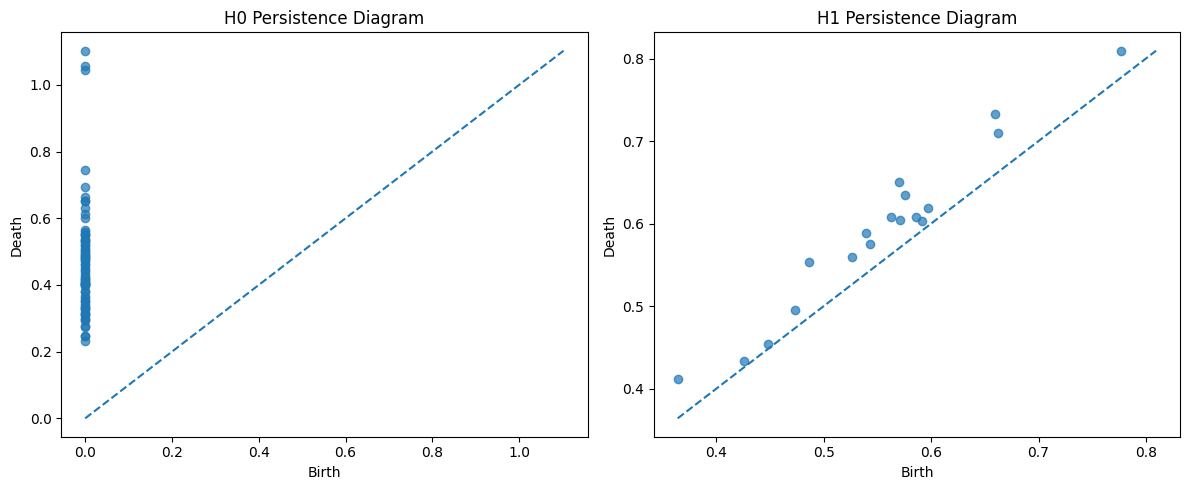

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, diagram, label in [
    (axes[0], H0, "H0 Persistence Diagram"),
    (axes[1], H1, "H1 Persistence Diagram")
]:

    finite = np.isfinite(diagram[:, 1])

    ax.scatter(
        diagram[finite, 0],
        diagram[finite, 1],
        alpha=0.7
    )

    if np.any(finite):
        minimum = min(
            diagram[finite, 0].min(),
            diagram[finite, 1].min()
        )
        maximum = max(
            diagram[finite, 0].max(),
            diagram[finite, 1].max()
        )

        ax.plot(
            [minimum, maximum],
            [minimum, maximum],
            linestyle="--"
        )

    ax.set_title(label)
    ax.set_xlabel("Birth")
    ax.set_ylabel("Death")

plt.tight_layout()

plt.savefig(
    results_dir / "persistence_diagrams.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [51]:
features_df.to_csv(
    results_dir / "topological_features.csv",
    index=False
)

print("FEATURE TABLE SAVED")
print(features_df)

FEATURE TABLE SAVED
  dimension  feature_count  finite_count  mean_lifetime  median_lifetime  \
0        H0             74            73       0.469010         0.443447   
1        H1             18            18       0.038388         0.033274   

   max_lifetime  total_persistence  
0      1.102251          34.237703  
1      0.081013           0.690979  


In [53]:
metadata = {
    "milestone": 7,
    "dataset": "ds005237",
    "participant": "sub-NDARINVYT858CBN",
    "atlas": "Schaefer 2018",
    "brain_regions": 74,
    "method": "Persistent Homology",
    "filtration": "Vietoris-Rips",
    "distance_metric": "Chord distance from Pearson correlation",
    "maximum_homology_dimension": 1,
    "H0_features": len(H0),
    "H1_features": len(H1),
    "topological_features": [
        "feature_count",
        "finite_count",
        "mean_lifetime",
        "median_lifetime",
        "max_lifetime",
        "total_persistence"
    ],
    "status": "Completed"
}

with open(
    results_dir / "milestone7_metadata.json",
    "w"
) as file:
    json.dump(metadata, file, indent=4)

print("MILESTONE 7 COMPLETED")
print(json.dumps(metadata, indent=4))

MILESTONE 7 COMPLETED
{
    "milestone": 7,
    "dataset": "ds005237",
    "participant": "sub-NDARINVYT858CBN",
    "atlas": "Schaefer 2018",
    "brain_regions": 74,
    "method": "Persistent Homology",
    "filtration": "Vietoris-Rips",
    "distance_metric": "Chord distance from Pearson correlation",
    "maximum_homology_dimension": 1,
    "H0_features": 74,
    "H1_features": 18,
    "topological_features": [
        "feature_count",
        "finite_count",
        "mean_lifetime",
        "median_lifetime",
        "max_lifetime",
        "total_persistence"
    ],
    "status": "Completed"
}
